In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import json
from tqdm import tqdm

def find_metrics(df):
    df["received"] = df["Delay"] > 0
    agent_delay = df.loc[df["agent"] == 0, :]
    agent_delay_received = agent_delay[agent_delay["received"]]
    avg_delay = agent_delay_received["Delay"].sum() / len(agent_delay_received.index)

    average_throughput = agent_delay_received["Packet Size"].sum()/(59941.0*len(agent_delay["seed"].unique()))

    agent_delay_not_waited = agent_delay[agent_delay["Wait"] == 0]
    agent_delay_not_waited["instantaneous_throughput"] = agent_delay_not_waited["received"] * agent_delay_not_waited["Packet Size"] / agent_delay_not_waited["Delay"]
    average_istantaneous_throughput = agent_delay_not_waited["instantaneous_throughput"].mean()

    agent_jitter = df.loc[df["agent"] == 1, :]
    jitter_delay_received = agent_jitter[agent_jitter["received"]]
    delay_diff = jitter_delay_received["Delay"].diff().abs()
    avg_jitter = delay_diff.mean()

    agent_reliability = df.loc[df["agent"] == 2, :]
    avg_prr = agent_reliability["received"].mean()
    return avg_delay, avg_jitter, avg_prr, average_throughput, average_istantaneous_throughput


In [14]:
probing_dir = "/media/signet/9b222db5-110f-45ae-b7ca-0f12241ce80b/MOAN_LowRate_Video/deleteme"

folders = os.listdir(probing_dir)

probing_df = []
for f in tqdm(folders):
    with open(os.path.join(probing_dir, f, "config.json")) as file:
        config = json.load(file)
    if int(config["mode"]) != 4:
        continue
    df = pd.read_csv(os.path.join(probing_dir, f, "evaluate_data.csv"))
    delay, jitter, prr, throughput, instantaneous_throughput = find_metrics(df)
    dict_row = {
        "Delay": delay,
        "Jitter": jitter,
        "PRR": prr,
        "Throughput": throughput,
        "Instantaneous Throughput": instantaneous_throughput,
        "Probing Period": float(config["probing_period"]),
        "seed": int(config["rng_stream"])
    }
    probing_df.append(dict_row)
probing_df = pd.DataFrame(probing_df)
out_df_probing = probing_df.groupby("Probing Period").mean().reset_index()
distance_dir = "/media/signet/9b222db5-110f-45ae-b7ca-0f12241ce80b/MOAN_LowRate_Video/deleteme"

folders = os.listdir(distance_dir)
distance_df = []
for f in tqdm(folders):
    with open(os.path.join(distance_dir, f, "config.json")) as file:
        config = json.load(file)
    if int(config["mode"]) != 3:
        continue
    df = pd.read_csv(os.path.join(distance_dir, f, "evaluate_data.csv"))
    delay, jitter, prr, throughput, instantaneous_throughput = find_metrics(df)
    dict_row = {
        "Delay": delay,
        "Jitter": jitter,
        "PRR": prr,
        "Throughput": throughput,
        "Instantaneous Throughput": instantaneous_throughput,
        "seed": int(config["rng_stream"]),
        "Distance": float(config["range_based_distance"])
    }
    distance_df.append(dict_row)
distance_df = pd.DataFrame(distance_df)
out_df_distance = distance_df.groupby("Distance").mean().reset_index()

100%|██████████| 465/465 [04:01<00:00,  1.92it/s]


In [ ]:
# out_df_probing.to_csv("out_df_probing_feb.csv", index=False)
# out_df_distance.to_csv("out_df_distance_feb.csv", index=False)
# probing_df.to_csv("probing_df_feb.csv", index=False)
# distance_df.to_csv("distance_df_feb.csv", index=False)

In [15]:
import json


data_dirs = "/media/signet/9b222db5-110f-45ae-b7ca-0f12241ce80b/MOAN_LowRate_Video/deleteme"
camps = os.listdir(data_dirs)

summaries = []        
for c in tqdm(camps):
    with open(os.path.join(data_dirs, c, "config.json")) as file:
        config = json.load(file)
    for i in range(5):
        if int(config["mode"]) == 2:
            evaluate_df = pd.read_csv(os.path.join(data_dirs, c, f"evaluate_data_{i}.csv"))
            delay, jitter, prr, throughput, instantaneous_throughput = find_metrics(evaluate_df)
            dict_row = {
                "ev_index": i,
                "Delay": delay,
                "Jitter": jitter,
                "PRR": prr,
                "Throughput": throughput,
                "Instantaneous_Throughput": instantaneous_throughput
            }
            summaries.append(dict_row)

sums = pd.DataFrame(summaries)
sums = sums.groupby("ev_index").mean().reset_index()
display(sums.sort_values(by=["PRR"], ascending=False)[["ev_index", "PRR"]])
display(sums.sort_values(by=["Jitter"], ascending=True)[["ev_index", "Jitter"]])
display(sums.sort_values(by=["Delay"], ascending=False)[["ev_index", "Delay"]])
display(sums.sort_values(by=["Throughput"], ascending=False)[["ev_index", "Throughput"]])
display(sums.sort_values(by=["Instantaneous_Throughput"], ascending=False)[["ev_index", "Instantaneous_Throughput"]])

chosen_index = 4
rl_summary = sums[sums["ev_index"] == chosen_index].iloc[0]

  0%|          | 0/465 [00:00<?, ?it/s]/tmp/ipykernel_836990/3755518819.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  agent_delay_not_waited["instantaneous_throughput"] = agent_delay_not_waited["received"] * agent_delay_not_waited["Packet Size"] / agent_delay_not_waited["Delay"]
/tmp/ipykernel_836990/3755518819.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  agent_delay_not_waited["instantaneous_throughput"] = agent_delay_not_waited["received"] * agent_delay_not_waited["Packet Size"] / agent_del

,ev_index,PRR
3,3,0.997314
2,2,0.997262
4,4,0.997212
1,1,0.991834
0,0,0.399308


,ev_index,Jitter
4,4,0.000073
2,2,0.000073
3,3,0.000073
1,1,0.079046
0,0,11.743294


,ev_index,Delay
3,3,0.833499
1,1,0.142560
4,4,0.128890
0,0,0.095855
2,2,0.049679


,ev_index,Throughput
3,3,0.081146
1,1,0.081042
0,0,0.080932
2,2,0.080929
4,4,0.080893


,ev_index,Instantaneous_Throughput
3,3,18875.672435
4,4,18851.360654
2,2,18639.541547
0,0,18595.086021
1,1,18529.932857


,Probing Period,Delay,Jitter,PRR,Throughput,Instantaneous Throughput,seed
0,0.10,0.465096,0.342988,0.108491,0.071154,16021.868275,8.0
1,0.25,0.628277,0.393045,0.108219,0.071376,16071.359362,8.0
2,0.50,0.570882,0.367878,0.108102,0.071041,15997.798956,8.0
3,0.75,0.568543,0.368339,0.108004,0.070833,15989.943659,8.0
4,1.00,0.369239,0.324282,0.108884,0.071068,16045.522320,8.0
5,10.00,0.408359,0.352664,0.108761,0.070963,16113.298122,8.0
6,30.00,0.673651,0.338917,0.109696,0.072365,16497.221409,8.0
7,60.00,0.473520,0.260694,0.114485,0.075111,17124.632647,8.0
8,90.00,0.617296,0.262534,0.101778,0.066259,15124.260899,8.0
9,180.00,0.499791,0.282503,0.087649,0.057692,13174.354204,8.0


/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and wil

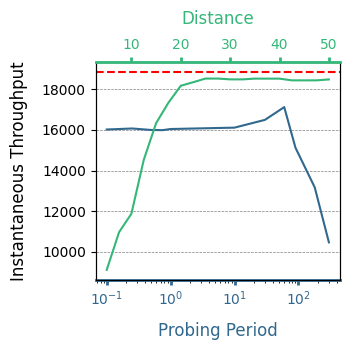

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and wil

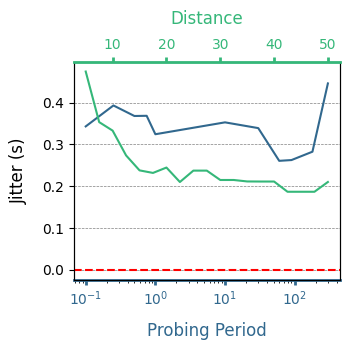

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and wil

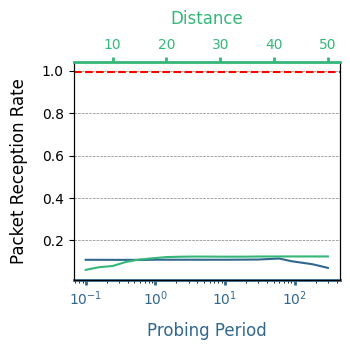

In [17]:
import tikzplotlib



import matplotlib.pylab as pylab
params = {'axes.labelsize': 12}
pylab.rcParams.update(params)



c1, c2 = sns.color_palette("viridis", 2)

fig, ax = plt.subplots(figsize=(3*1.2,3*1.2))
labelpad = 10
metric_1 = "Instantaneous Throughput"
plt.ylabel(metric_1, labelpad=labelpad)
ax2 = ax.twiny()
display(out_df_probing)
sns.lineplot(out_df_probing, x = "Probing Period", y = metric_1, ax=ax, color=c1)
# sns.scatterplot(out_df_probing.groupby("Probing Period").mean(), x = "Probing Period", y = metric_1, ax=ax, color=c1)
ax.set_xscale("log")
sns.lineplot(out_df_distance, x = "Distance", y = metric_1, ax=ax2, color=c2)
x_lim = plt.xlim()
ax2.plot(x_lim, [18875.67243519089, 18875.67243519089], 'r--')
ax2.set_xlim(x_lim)
ax.xaxis.label.set_color(c1)
ax2.xaxis.label.set_color(c2)
ax.tick_params(axis='x', colors=c1, width=2)
ax2.tick_params(axis='x', colors=c2, width=2)
ax.spines['bottom'].set_color(c1)
ax.spines['bottom'].set_linewidth(2)
ax2.spines['top'].set_color(c2)
ax2.spines['top'].set_linewidth(2)
ax.xaxis.labelpad = labelpad
ax2.xaxis.labelpad = labelpad
ax.grid(visible=True, which='major', color='gray', axis="y", linestyle='--', linewidth=0.5)
plt.tight_layout()
# plt.savefig("Delay.pdf", bbox_inches='tight')
# plt.savefig("Delay.png", dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(3*1.2,3*1.2))
plt.ylabel("Jitter (s)", labelpad=labelpad)
ax2 = ax.twiny()
sns.lineplot(out_df_probing, x = "Probing Period", y = "Jitter", ax=ax, color=c1)
# sns.scatterplot(out_df_probing.groupby("Probing Period").mean(), x = "Probing Period", y = "Jitter", ax=ax, color=c1)
ax.set_xscale("log")
sns.lineplot(out_df_distance, x = "Distance", y = "Jitter", ax=ax2, color=c2)
x_lim = plt.xlim()
ax.xaxis.label.set_color(c1)
ax2.xaxis.label.set_color(c2)
ax.tick_params(axis='x', colors=c1, width=2)
ax2.tick_params(axis='x', colors=c2, width=2)
ax.spines['bottom'].set_color(c1)
ax.spines['bottom'].set_linewidth(2)
ax2.spines['top'].set_color(c2)
ax2.spines['top'].set_linewidth(2)
ax.xaxis.labelpad = labelpad
ax2.xaxis.labelpad = labelpad
ax2.plot(x_lim, [rl_summary["Jitter"], rl_summary["Jitter"]], 'r--')
ax.grid(visible=True, which='major', color='gray', axis="y", linestyle='--', linewidth=0.5)
ax2.set_xlim(x_lim)
plt.tight_layout()
# plt.savefig("jitter.pdf", bbox_inches='tight')
# plt.savefig("jitter.png", dpi=300, bbox_inches='tight')
plt.show()


fig, ax = plt.subplots(figsize=(3*1.2,3*1.2))
plt.ylabel("Packet Reception Rate", labelpad=labelpad)
ax2 = ax.twiny()
sns.lineplot(out_df_probing, x = "Probing Period", y = "PRR", ax=ax, color=c1)
# sns.scatterplot(out_df_probing.groupby("Probing Period").mean(), x = "Probing Period", y = "PRR", ax=ax, color=c1)
ax.set_xscale("log")
sns.lineplot(out_df_distance, x = "Distance", y = "PRR", ax=ax2, color=c2)
x_lim = plt.xlim()
ax.xaxis.label.set_color(c1)
ax2.xaxis.label.set_color(c2)
ax.tick_params(axis='x', colors=c1, width=2)
ax2.tick_params(axis='x', colors=c2, width=2)
ax.spines['bottom'].set_color(c1)
ax.spines['bottom'].set_linewidth(2)
ax2.spines['top'].set_color(c2)
ax2.spines['top'].set_linewidth(2)
ax.xaxis.labelpad = labelpad
ax2.xaxis.labelpad = labelpad
ax.grid(visible=True, which='major', color='gray', axis="y", linestyle='--', linewidth=0.5)
ax2.plot(x_lim, [rl_summary["PRR"], rl_summary["PRR"]], 'r--')
ax2.set_xlim(x_lim)
plt.tight_layout()
# plt.savefig("prr.pdf", bbox_inches='tight')
# plt.savefig("prr.png", dpi=300, bbox_inches='tight')
plt.show()

In [24]:
probing_df.groupby("Probing Period").mean().max()

Delay                           0.947310
Jitter                          0.445727
PRR                             0.114485
Throughput                      0.075111
Instantaneous Throughput    17124.632647
seed                            8.000000
dtype: float64

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


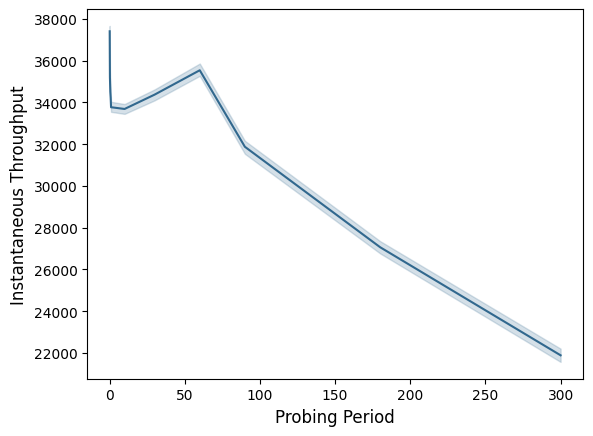

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


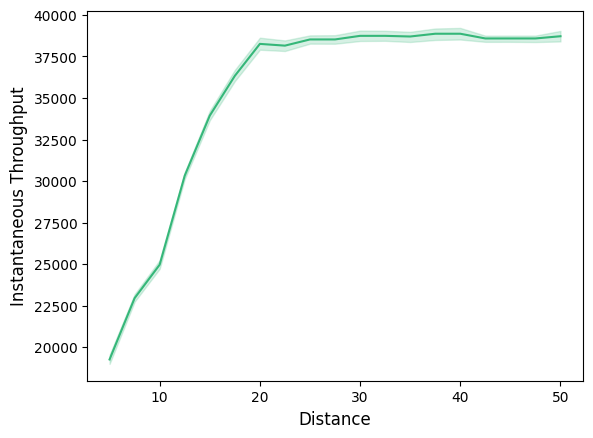

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


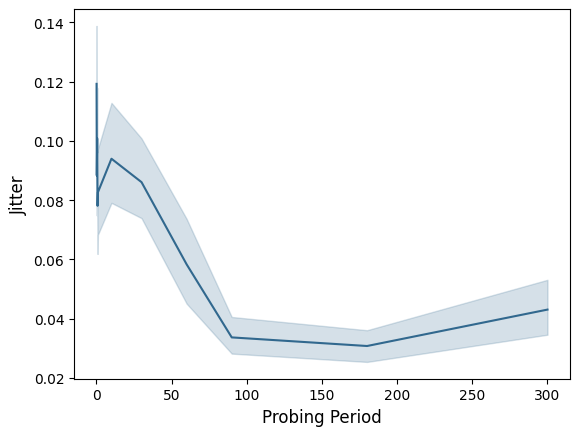

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


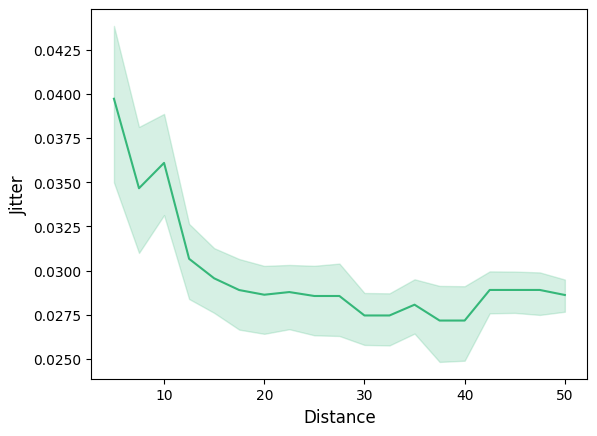

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


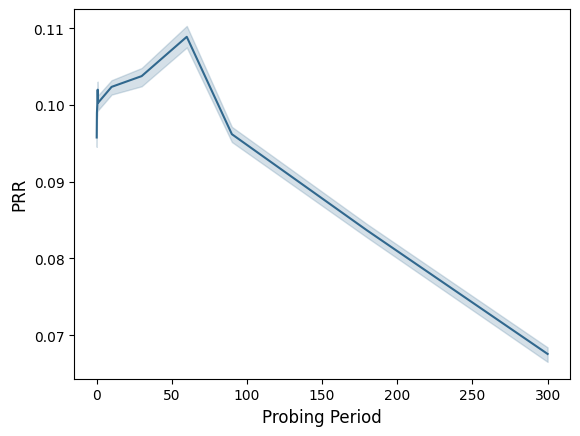

/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/signet/anaconda3/envs/plot/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


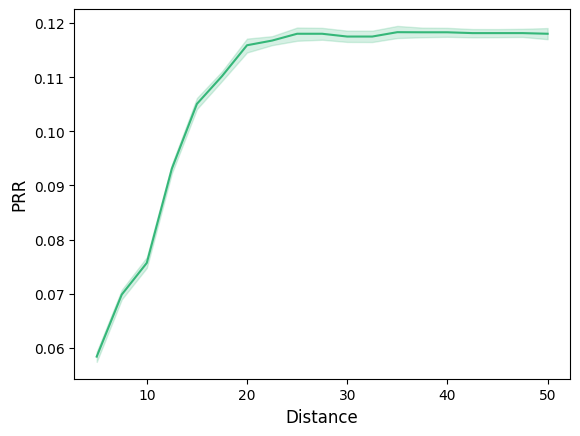

In [13]:
sns.lineplot(probing_df, x = "Probing Period", y = metric_1, color=c1)
tikzplotlib.save("/home/signet/test_out/probing_throughput_feb.tex")
plt.show()

sns.lineplot(distance_df, x = "Distance", y = metric_1, color=c2)
tikzplotlib.save("/home/signet/test_out/distance_throughput_feb.tex")
plt.show()

sns.lineplot(probing_df, x = "Probing Period", y = "Jitter", color=c1)
tikzplotlib.save("/home/signet/test_out/probing_jitter.tex")
plt.show()

sns.lineplot(distance_df, x = "Distance", y = "Jitter", color=c2)
tikzplotlib.save("/home/signet/test_out/distance_jitter.tex")
plt.show()

sns.lineplot(probing_df, x = "Probing Period", y = "PRR", color=c1)
tikzplotlib.save("/home/signet/test_out/probing_prr.tex")
plt.show()

sns.lineplot(distance_df, x = "Distance", y = "PRR", color=c2)
tikzplotlib.save("/home/signet/test_out/distance_prr.tex")
plt.show()

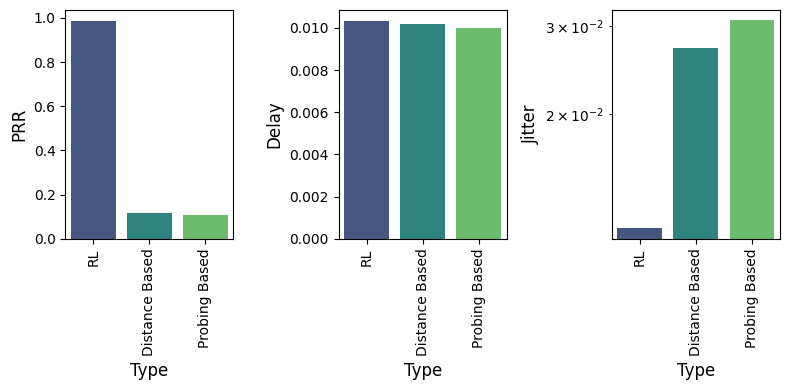

In [7]:
dicts = []

summary_rl = rl_summary
summary_db = out_df_distance.copy()
summary_db["PRR"] = -summary_db["PRR"]
summary_db = summary_db.min()
summary_db["PRR"] = -summary_db["PRR"]

summary_pb = out_df_probing.copy()
summary_pb["PRR"] = -summary_pb["PRR"]
summary_pb = summary_pb.min()
summary_pb["PRR"] = -summary_pb["PRR"]

metrics = ["PRR", "Delay", "Jitter"]
summaries = [summary_rl, summary_db, summary_pb]
summaries_name = ["RL", "Distance Based", "Probing Based"]
for m in metrics:
    for i in range(len(summaries)):
        dicts.append({
            "Metric": m,
            "Value": summaries[i][m],
            "Type": summaries_name[i]
        })

summary_df = pd.DataFrame(dicts)
summary_df
fig, ax = plt.subplots(1,3, figsize=(8, 4))

for i, m in enumerate(metrics):
    sns.barplot(x="Type", y="Value", data=summary_df[summary_df["Metric"] == m], ax=ax[i], palette="viridis")
    ax[i].set_ylabel(m)
    ax[i].tick_params(axis='x', rotation=90)

ax[2].set_yscale("log")

tikzplotlib.save("/home/signet/test_out/summary.tex")

plt.tight_layout()
plt.show()

In [8]:
nohup python runner.py --rng_seed 0 --no-compile &
nohup python runner.py --rng_seed 1 --no-compile &
nohup python runner.py --rng_seed 2 --no-compile &
nohup python runner.py --rng_seed 3 --no-compile &
nohup python runner.py --rng_seed 4 --no-compile &
nohup python runner.py --rng_seed 5 --no-compile &
nohup python runner.py --rng_seed 6 --no-compile &
nohup python runner.py --rng_seed 7 --no-compile &
nohup python runner.py --rng_seed 8 --no-compile &
nohup python runner.py --rng_seed 9 --no-compile &
nohup python runner.py --rng_seed 10 --no-compile &
nohup python runner.py --rng_seed 11 --no-compile &
nohup python runner.py --rng_seed 12 --no-compile &
nohup python runner.py --rng_seed 13 --no-compile &
nohup python runner.py --rng_seed 14 --no-compile &
nohup python runner.py --rng_seed 15 --no-compile &

SyntaxError: invalid syntax (4139436540.py, line 1)